In [1]:
import numpy as np
import matplotlib.pyplot as plt

from numcosmo_ep2 import growth

# Exercise 1. Compute and validate linear growth

In [2]:
aEval = np.logspace(-4, 0, 200)
G1_EdS,  D_EdS,  f_EdS  = growth.linearGrowth(aEval, 1.0, 0.0)
G1_lCDM, D_lCDM, f_lCDM = growth.linearGrowth(aEval, 0.3, 0.7)
G1_oCDM, D_oCDM, f_oCDM = growth.linearGrowth(aEval, 0.3, 0.0)

In [3]:
print("D(a) EdS maximum relative error = ", np.max(np.abs(D_EdS / aEval - 1.0)))
print("f(a) EdS maximum relative error = ", np.max(np.abs(f_EdS - 1.0)))

D(a) EdS maximum relative error =  1.9925725514013948e-08
f(a) EdS maximum relative error =  2.220446049250313e-16


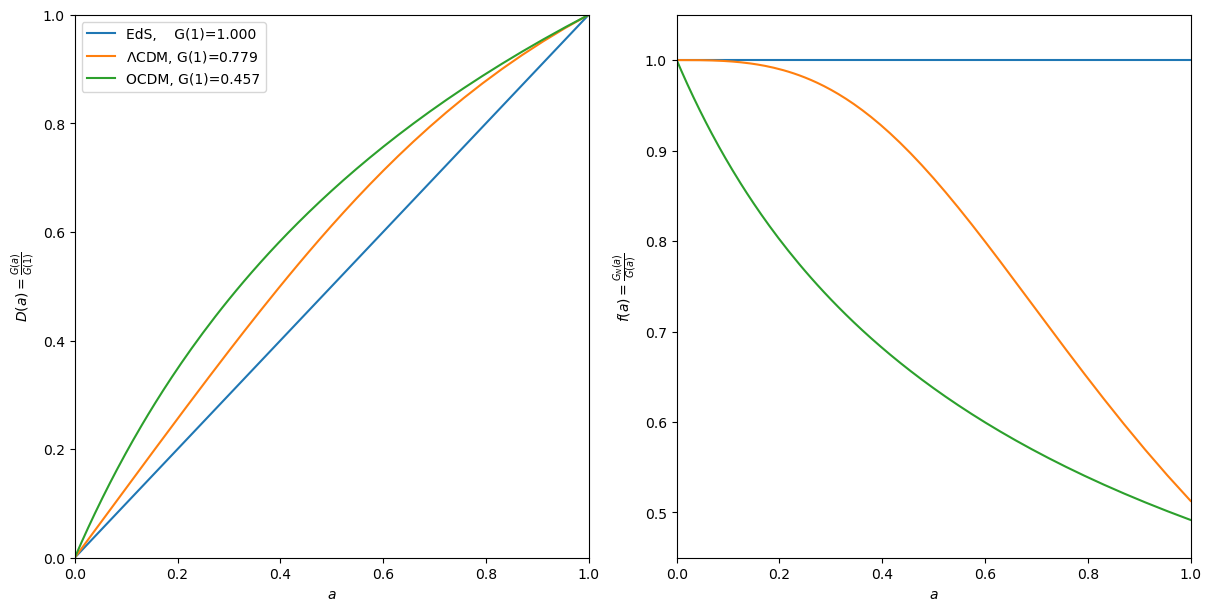

In [4]:
fig, ax = plt.subplots(ncols=2, sharex=True, figsize=(12, 6), layout="constrained")
ax[0].plot(aEval, D_EdS, c="C0", label="EdS,    "+f"G(1)={G1_EdS:.3f}")
ax[0].plot(aEval, D_lCDM, c="C1", label=r"$\Lambda$CDM, "+f"G(1)={G1_lCDM:.3f}")
ax[0].plot(aEval, D_oCDM, c="C2", label="OCDM, "+f"G(1)={G1_oCDM:.3f}")

ax[1].plot(aEval, f_EdS, c="C0", label="EdS")
ax[1].plot(aEval, f_lCDM, c="C1", label=r"$\Lambda$CDM")
ax[1].plot(aEval, f_oCDM, c="C2", label="open CDM")

ax[0].set_xlim(0,1)
ax[1].set_xlim(0,1)
ax[0].set_ylim(0,1)
ax[1].set_ylim(0.45,1.05)

ax[0].set_ylabel(r"$D(a)=\frac{G(a)}{G(1)}$")
ax[1].set_ylabel(r"$f(a)=\frac{G_N(a)}{G(a)}$")
ax[0].set_xlabel(r"$a$")
ax[1].set_xlabel(r"$a$")
ax[0].legend()

plt.savefig("../outputs/figures/linearGrowth.png", dpi=200)
plt.show()

## Testing errors in EdS growth using the ODE solution

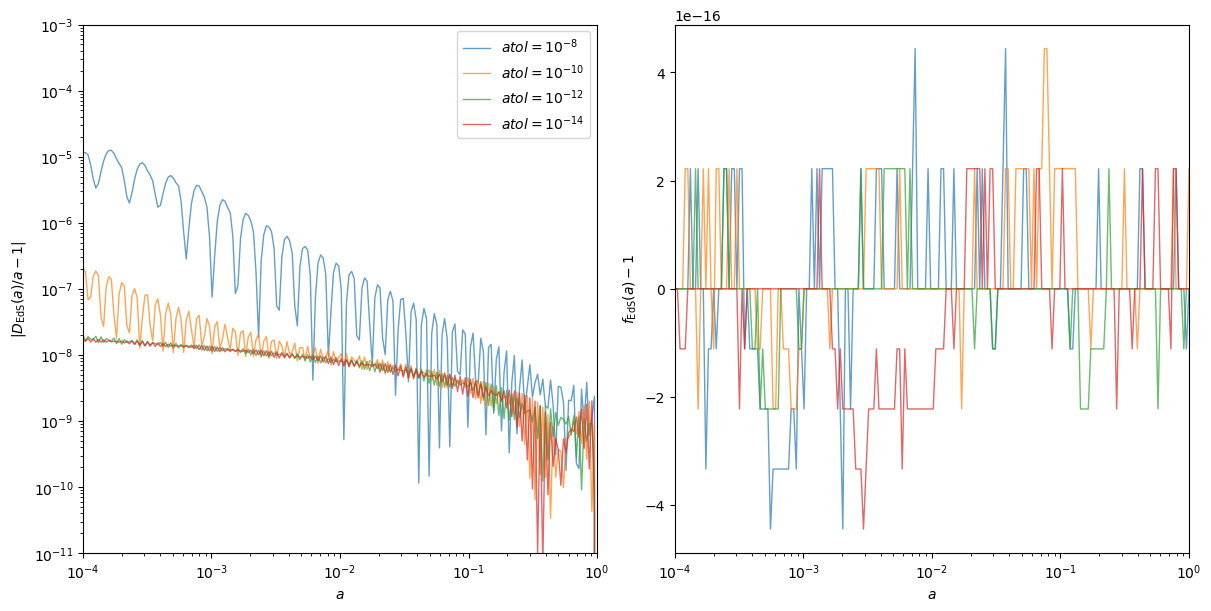

In [5]:
atol_values = [1e-8, 1e-10, 1e-12, 1e-14]
aEval = np.logspace(-4, 0, 200)

_, D0, f0 = growth.linearGrowth(aEval, 1.0, 0.0, atol=atol_values[0])
_, D1, f1 = growth.linearGrowth(aEval, 1.0, 0.0, atol=atol_values[1])
_, D2, f2 = growth.linearGrowth(aEval, 1.0, 0.0, atol=atol_values[2])
_, D3, f3 = growth.linearGrowth(aEval, 1.0, 0.0, atol=atol_values[3])

fig, ax = plt.subplots(ncols=2, sharex=True, figsize=(12, 6), layout="constrained")
ax[0].plot(aEval, np.abs(D0/aEval-1), c="C0", label=r"$atol=10^{-8}$",  lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D1/aEval-1), c="C1", label=r"$atol=10^{-10}$", lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D2/aEval-1), c="C2", label=r"$atol=10^{-12}$", lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D3/aEval-1), c="C3", label=r"$atol=10^{-14}$", lw=1, alpha=.7)

ax[1].plot(aEval, f0-1, c="C0", lw=1, alpha=.7)
ax[1].plot(aEval, f1-1, c="C1", lw=1, alpha=.7)
ax[1].plot(aEval, f2-1, c="C2", lw=1, alpha=.7)
ax[1].plot(aEval, f3-1, c="C3", lw=1, alpha=.7)

ax[0].set_xlim(1e-4, 1)
ax[1].set_xlim(1e-4, 1)
ax[0].set_ylim(1e-11, 1e-3)
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[1].set_xscale("log")

ax[0].set_ylabel(r"$|D_\mathrm{EdS}(a)/a-1|$")
ax[1].set_ylabel(r"$f_\mathrm{EdS}(a)-1$")
ax[0].set_xlabel(r"$a$")
ax[1].set_xlabel(r"$a$")
ax[0].legend()

plt.savefig("../outputs/figures/atol_error.png", dpi=200)
plt.show()

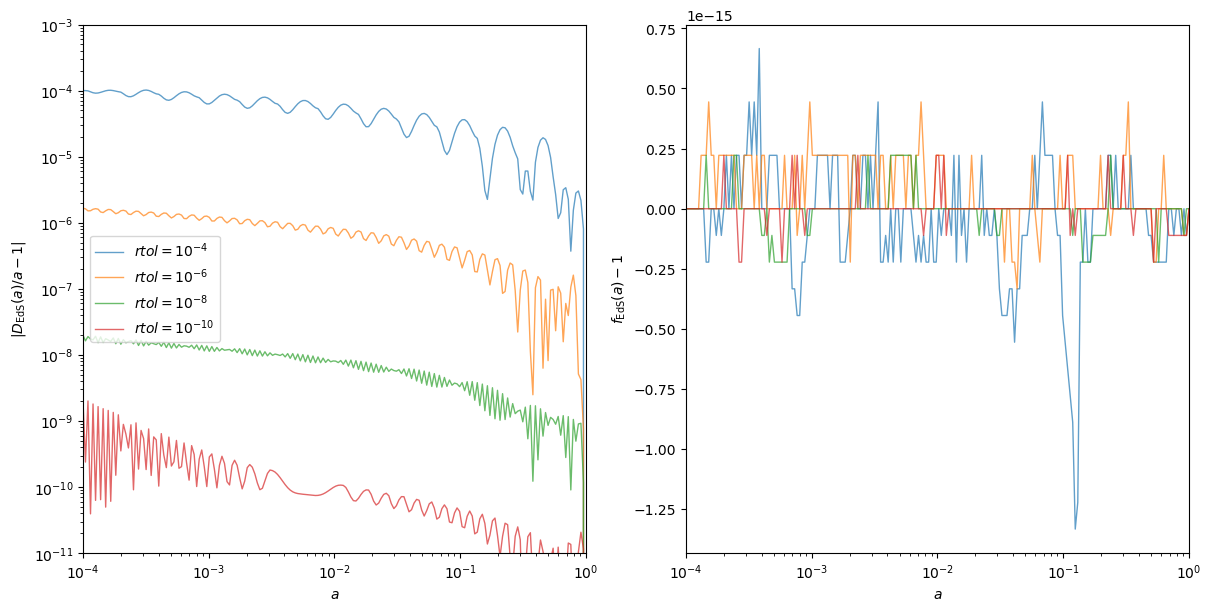

In [6]:
rtol_values = [1e-4, 1e-6, 1e-8, 1e-10]
aEval = np.logspace(-4, 0, 200)

_, D0, f0 = growth.linearGrowth(aEval, 1.0, 0.0, rtol=rtol_values[0])
_, D1, f1 = growth.linearGrowth(aEval, 1.0, 0.0, rtol=rtol_values[1])
_, D2, f2 = growth.linearGrowth(aEval, 1.0, 0.0, rtol=rtol_values[2])
_, D3, f3 = growth.linearGrowth(aEval, 1.0, 0.0, rtol=rtol_values[3])

fig, ax = plt.subplots(ncols=2, sharex=True, figsize=(12, 6), layout="constrained")
ax[0].plot(aEval, np.abs(D0/aEval-1), c="C0", label=r"$rtol=10^{-4}$",  lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D1/aEval-1), c="C1", label=r"$rtol=10^{-6}$",  lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D2/aEval-1), c="C2", label=r"$rtol=10^{-8}$",  lw=1, alpha=.7)
ax[0].plot(aEval, np.abs(D3/aEval-1), c="C3", label=r"$rtol=10^{-10}$", lw=1, alpha=.7)

ax[1].plot(aEval, f0-1, c="C0", lw=1, alpha=.7)
ax[1].plot(aEval, f1-1, c="C1", lw=1, alpha=.7)
ax[1].plot(aEval, f2-1, c="C2", lw=1, alpha=.7)
ax[1].plot(aEval, f3-1, c="C3", lw=1, alpha=.7)

ax[0].set_xlim(1e-4, 1)
ax[1].set_xlim(1e-4, 1)
ax[0].set_ylim(1e-11, 1e-3)
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[1].set_xscale("log")

ax[0].set_ylabel(r"$|D_\mathrm{EdS}(a)/a-1|$")
ax[1].set_ylabel(r"$f_\mathrm{EdS}(a)-1$")
ax[0].set_xlabel(r"$a$")
ax[1].set_xlabel(r"$a$")
ax[0].legend()

plt.savefig("../outputs/figures/rtol_error.png", dpi=200)
plt.show()

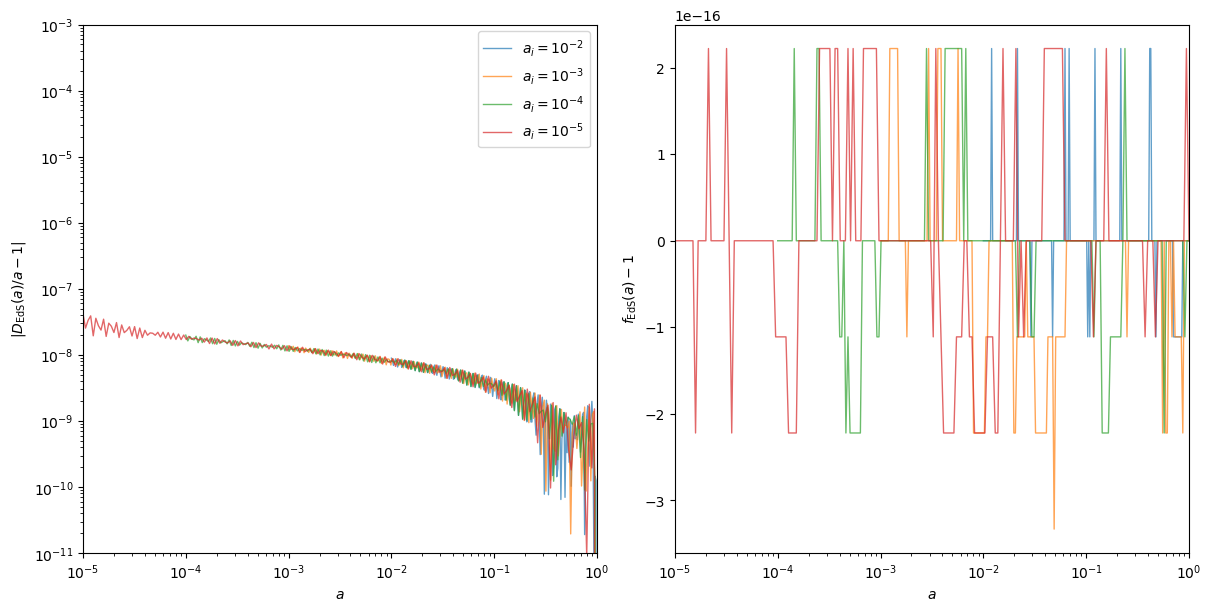

In [7]:
ai_values = [1e-2, 1e-3, 1e-4, 1e-5]
aEval0 = np.logspace(-2, 0, 200)
_, D0, f0 = growth.linearGrowth(aEval0, 1.0, 0.0, ai=ai_values[0])
aEval1 = np.logspace(-3, 0, 200)
_, D1, f1 = growth.linearGrowth(aEval1, 1.0, 0.0, ai=ai_values[1])
aEval2 = np.logspace(-4, 0, 200)
_, D2, f2 = growth.linearGrowth(aEval2, 1.0, 0.0, ai=ai_values[2])
aEval3 = np.logspace(-5, 0, 200)
_, D3, f3 = growth.linearGrowth(aEval3, 1.0, 0.0, ai=ai_values[3])

fig, ax = plt.subplots(ncols=2, sharex=True, figsize=(12, 6), layout="constrained")
ax[0].plot(aEval0, np.abs(D0/aEval0-1), c="C0", label=r"$a_i=10^{-2}$", lw=1, alpha=.7)
ax[0].plot(aEval1, np.abs(D1/aEval1-1), c="C1", label=r"$a_i=10^{-3}$", lw=1, alpha=.7)
ax[0].plot(aEval2, np.abs(D2/aEval2-1), c="C2", label=r"$a_i=10^{-4}$", lw=1, alpha=.7)
ax[0].plot(aEval3, np.abs(D3/aEval3-1), c="C3", label=r"$a_i=10^{-5}$", lw=1, alpha=.7)

ax[1].plot(aEval0, f0-1, c="C0", lw=1, alpha=.7)
ax[1].plot(aEval1, f1-1, c="C1", lw=1, alpha=.7)
ax[1].plot(aEval2, f2-1, c="C2", lw=1, alpha=.7)
ax[1].plot(aEval3, f3-1, c="C3", lw=1, alpha=.7)

ax[0].set_xlim(1e-5, 1)
ax[1].set_xlim(1e-5, 1)
ax[0].set_ylim(1e-11, 1e-3)
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[1].set_xscale("log")

ax[0].set_ylabel(r"$|D_\mathrm{EdS}(a)/a-1|$")
ax[1].set_ylabel(r"$f_\mathrm{EdS}(a)-1$")
ax[0].set_xlabel(r"$a$")
ax[1].set_xlabel(r"$a$")
ax[0].legend()

plt.savefig("../outputs/figures/initial_error.png", dpi=200)
plt.show()

## Comparision of ODE and quadrature $D(a)$ estimation

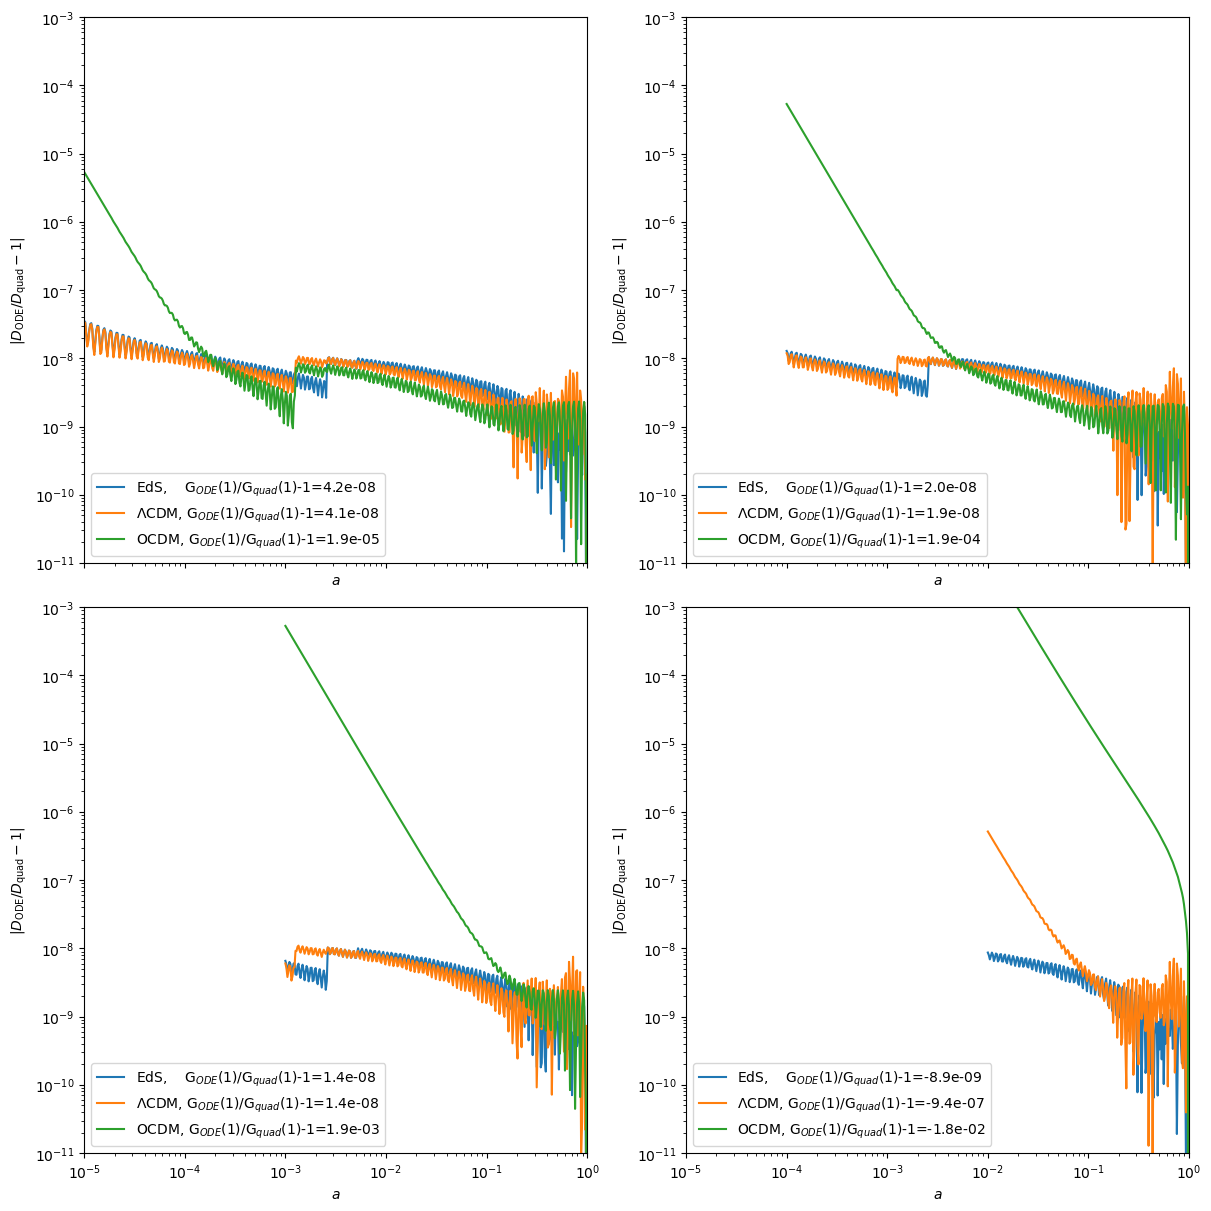

In [8]:
fig, ax = plt.subplots(nrows=2, ncols=2, sharex=True, figsize=(12, 12), layout="constrained")

# ai = 1e-5 -----------------------------------------------------------
aEval = np.logspace(-5, 0, 500)
G1_EdS,   D_EdS,  _ = growth.linearGrowth(aEval, 1.0, 0.0, ai=aEval[0])
G1_lCDM,  D_lCDM, _ = growth.linearGrowth(aEval, 0.3, 0.7, ai=aEval[0])
G1_oCDM,  D_oCDM, _ = growth.linearGrowth(aEval, 0.3, 0.0, ai=aEval[0])
G1q_EdS,  Dq_EdS  = growth.linearGrowthQuad(aEval, 1.0, 0.0)
G1q_lCDM, Dq_lCDM = growth.linearGrowthQuad(aEval, 0.3, 0.7)
G1q_oCDM, Dq_oCDM = growth.linearGrowthQuad(aEval, 0.3, 0.0)

ax[0][0].plot(aEval, np.abs(D_EdS/Dq_EdS-1), label="EdS,    "+fr"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_EdS/G1q_EdS-1:.1e}")
ax[0][0].plot(aEval, np.abs(D_lCDM/Dq_lCDM-1), c="C1", label=r"$\Lambda$CDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_lCDM/G1q_lCDM-1:.1e}")
ax[0][0].plot(aEval, np.abs(D_oCDM/Dq_oCDM-1), c="C2", label="OCDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_oCDM/G1q_oCDM-1:.1e}")

ax[0][0].set_xlim(1e-5, 1)
ax[0][0].set_ylim(1e-11, 1e-3)
ax[0][0].set_xscale("log")
ax[0][0].set_yscale("log")
ax[0][0].set_xlabel(r"$a$")
ax[0][0].set_ylabel(r"$|D_\mathrm{ODE}/D_\mathrm{quad}-1|$")

# ai = 1e-4 -----------------------------------------------------------
aEval = np.logspace(-4, 0, 400)
G1_EdS,   D_EdS,  _ = growth.linearGrowth(aEval, 1.0, 0.0, ai=aEval[0])
G1_lCDM,  D_lCDM, _ = growth.linearGrowth(aEval, 0.3, 0.7, ai=aEval[0])
G1_oCDM,  D_oCDM, _ = growth.linearGrowth(aEval, 0.3, 0.0, ai=aEval[0])
G1q_EdS,  Dq_EdS  = growth.linearGrowthQuad(aEval, 1.0, 0.0)
G1q_lCDM, Dq_lCDM = growth.linearGrowthQuad(aEval, 0.3, 0.7)
G1q_oCDM, Dq_oCDM = growth.linearGrowthQuad(aEval, 0.3, 0.0)

ax[0][1].plot(aEval, np.abs(D_EdS/Dq_EdS-1), label="EdS,    "+fr"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_EdS/G1q_EdS-1:.1e}")
ax[0][1].plot(aEval, np.abs(D_lCDM/Dq_lCDM-1), c="C1", label=r"$\Lambda$CDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_lCDM/G1q_lCDM-1:.1e}")
ax[0][1].plot(aEval, np.abs(D_oCDM/Dq_oCDM-1), c="C2", label="OCDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_oCDM/G1q_oCDM-1:.1e}")

ax[0][1].set_xlim(1e-5, 1)
ax[0][1].set_ylim(1e-11, 1e-3)
ax[0][1].set_xscale("log")
ax[0][1].set_yscale("log")
ax[0][1].set_xlabel(r"$a$")
ax[0][1].set_ylabel(r"$|D_\mathrm{ODE}/D_\mathrm{quad}-1|$")

# ai = 1e-3 -----------------------------------------------------------
aEval = np.logspace(-3, 0, 300)
G1_EdS,   D_EdS,  _ = growth.linearGrowth(aEval, 1.0, 0.0, ai=aEval[0])
G1_lCDM,  D_lCDM, _ = growth.linearGrowth(aEval, 0.3, 0.7, ai=aEval[0])
G1_oCDM,  D_oCDM, _ = growth.linearGrowth(aEval, 0.3, 0.0, ai=aEval[0])
G1q_EdS,  Dq_EdS  = growth.linearGrowthQuad(aEval, 1.0, 0.0)
G1q_lCDM, Dq_lCDM = growth.linearGrowthQuad(aEval, 0.3, 0.7)
G1q_oCDM, Dq_oCDM = growth.linearGrowthQuad(aEval, 0.3, 0.0)

ax[1][0].plot(aEval, np.abs(D_EdS/Dq_EdS-1), label="EdS,    "+fr"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_EdS/G1q_EdS-1:.1e}")
ax[1][0].plot(aEval, np.abs(D_lCDM/Dq_lCDM-1), c="C1", label=r"$\Lambda$CDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_lCDM/G1q_lCDM-1:.1e}")
ax[1][0].plot(aEval, np.abs(D_oCDM/Dq_oCDM-1), c="C2", label="OCDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1_oCDM/G1q_oCDM-1:.1e}")

ax[1][0].set_xlim(1e-5, 1)
ax[1][0].set_ylim(1e-11, 1e-3)
ax[1][0].set_xscale("log")
ax[1][0].set_yscale("log")
ax[1][0].set_xlabel(r"$a$")
ax[1][0].set_ylabel(r"$|D_\mathrm{ODE}/D_\mathrm{quad}-1|$")

# ai = 1e-2 -----------------------------------------------------------
aEval = np.logspace(-2, 0, 200)
G1_EdS,   D_EdS,  _ = growth.linearGrowth(aEval, 1.0, 0.0, ai=aEval[0])
G1_lCDM,  D_lCDM, _ = growth.linearGrowth(aEval, 0.3, 0.7, ai=aEval[0])
G1_oCDM,  D_oCDM, _ = growth.linearGrowth(aEval, 0.3, 0.0, ai=aEval[0])
G1q_EdS,  Dq_EdS  = growth.linearGrowthQuad(aEval, 1.0, 0.0)
G1q_lCDM, Dq_lCDM = growth.linearGrowthQuad(aEval, 0.3, 0.7)
G1q_oCDM, Dq_oCDM = growth.linearGrowthQuad(aEval, 0.3, 0.0)

ax[1][1].plot(aEval, np.abs(D_EdS/Dq_EdS-1), label="EdS,    "+fr"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1q_EdS/G1_EdS-1:.1e}")
ax[1][1].plot(aEval, np.abs(D_lCDM/Dq_lCDM-1), c="C1", label=r"$\Lambda$CDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1q_lCDM/G1_lCDM-1:.1e}")
ax[1][1].plot(aEval, np.abs(D_oCDM/Dq_oCDM-1), c="C2", label="OCDM, "+f"G$_{{ODE}}$(1)/G$_{{quad}}$(1)-1={G1q_oCDM/G1_oCDM-1:.1e}")

ax[1][1].set_xlim(1e-5, 1)
ax[1][1].set_ylim(1e-11, 1e-3)
ax[1][1].set_xscale("log")
ax[1][1].set_yscale("log")
ax[1][1].set_xlabel(r"$a$")
ax[1][1].set_ylabel(r"$|D_\mathrm{ODE}/D_\mathrm{quad}-1|$")

ax[0][0].legend(loc='lower left')
ax[0][1].legend(loc='lower left')
ax[1][0].legend(loc='lower left')
ax[1][1].legend(loc='lower left')

plt.savefig("../outputs/figures/quad_ODE_error.png", dpi=200)
plt.show()